In [57]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats
import statistics
import math
import sys
from pylab import *
from math import log
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
from generate_data import *
from train_models import *
from honest_trees import *
%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


This notebook is used to run the simulation experiments for fitting sparse a sum of square model with continuous features. The structure of this notebook is as follows: (a) We first fit different tree-based estimators on a linear model with X generated from Uniform([0,1]^d). We then plot the generalisation performance of these different estimators. 

# Examine Generalisation performance for Log Addisitve Regression Model

In [13]:
def log_list(t):
    return [log(x,math.e) for x in t]

In [14]:
def get_best_fit_line(x,y):
    m, b = np.polyfit(x, y, 1)
    return [m,b]

In [60]:
n_train = [100,200,400,800,1600,3200]
n_test = 500
d = 50
beta = 1
sigma = 0.1
sparsity = [10,20]
n_avg = 100

In [59]:
# Initialize matrix for honest CART 
honest_CART_scores = []
honest_CART_error_bar = []
honest_CART_best_fit = []
#Initialize matrix for honest CART with CCP 
#honest_CART_CCP_scores = []
#honest_CART_CCP_error_bar = []

#Initialize matrix for dishonest CART 
CART_scores = []
CART_error_bar = []
CART_best_fit = []

#Initialize Matrix for dishonest CART with CCP 
#CART_CCP_scores = []
#CART_CCP_error_bar = []

#Initialize Matrix for RF
RF_scores = []
RF_error_bar = []
RF_best_fit = []
#Initialize matrix for theoretical lower bound 


In [ ]:
#Fit results tracking MSE 
for s in sparsity: 
    honest_CART_s = []
    honest_CART_s_error_bar = []
    
    
    
    #honest_CART_CCP_s = []
    #honest_CART_CCP_s_error_bar = []
    CART_s = []
    CART_s_error_bar = []
  
    
    #CART_CCP_s = []
    #CART_CCP_s_error_bar = []
    
    RF_s = []
    RF_s_error_bar = []

    
    for n in tqdm(n_train):
        honest_CART = []
        #honest_CART_CCP = []
        CART = []
        #CART_CCP = []
        RF = []
        for j in range(n_avg):
            #Create data to fit models 
            X_train = sample_uniform_X(n,d)
            X_honest = sample_uniform_X(n,d)
            X_test = sample_uniform_X(n_test,d)
            
            
            y_train = exponential_model(X_train,s,beta,sigma)
            y_honest = exponential_model(X_honest,s,beta,sigma)
            y_test = exponential_model(X_test,s,beta,0) #zero noise since we want to measure ||\hat{f} - f||_2
            
            
            
            #Fit and predict for all versions of CART
            honest_CART_MSE,CART_MSE =  train_all_models(X_train,y_train,X_honest,y_honest,X_test,y_test,sigma,k = 5)
            honest_CART.append(honest_CART_MSE)
            
            
            
            #honest_CART_CCP.append(honest_CART_CCP_MSE)
            CART.append(CART_MSE)
            #CART_CCP.append(CART_CCP_MSE)
            
            #Fit and predict for RF
            rf = RandomForestRegressor(n_estimators = 100,max_features = 0.33)
            rf.fit(X_train,y_train)
            rf_preds = rf.predict(X_test)
            RF.append(mean_squared_error(y_test,rf_preds))
            
            
            
        #Store Performance in matrix
        honest_CART_s.append(statistics.mean(honest_CART))
        honest_CART_s_error_bar.append(statistics.stdev(honest_CART))
        
        #honest_CART_CCP_s.append(statistics.mean(honest_CART_CCP))
        #honest_CART_CCP_s_error_bar.append(statistics.stdev(honest_CART_CCP))
        
        CART_s.append(statistics.mean(CART))
        CART_s_error_bar.append(statistics.stdev(CART))
        
        #CART_CCP_s.append(statistics.mean(CART_CCP))
        #CART_CCP_s_error_bar.append(statistics.stdev(CART_CCP))
        
        RF_s.append(statistics.mean(RF))
        RF_s_error_bar.append(statistics.stdev(RF))
        

    
    #save results 
    honest_CART_scores.append(honest_CART_s)
    #honest_CART_CCP_scores.append(honest_CART_CCP_s)
    CART_scores.append(CART_s)
    #CART_CCP_scores.append(CART_CCP_s)
    RF_scores.append(RF_s)
    
    
    honest_CART_error_bar.append(honest_CART_s_error_bar)
    #honest_CART_CCP_error_bar.append(honest_CART_CCP_s_error_bar)
    CART_error_bar.append(CART_s_error_bar)
    #CART_CCP_error_bar.append(CART_CCP_s_error_bar) 
    RF_error_bar.append(RF_s_error_bar)


 83%|████████▎ | 5/6 [11:07<02:13, 133.52s/it]


KeyboardInterrupt: 

In [61]:
#Results under SEM to reduce varaince
for s in sparsity: 
    honest_CART_s = []
    honest_CART_s_error_bar = []
    
    
    
    #honest_CART_CCP_s = []
    #honest_CART_CCP_s_error_bar = []
    CART_s = []
    CART_s_error_bar = []
  
    
    #CART_CCP_s = []
    #CART_CCP_s_error_bar = []
    
    RF_s = []
    RF_s_error_bar = []

    
    for n in tqdm(n_train):
        honest_CART = []
        #honest_CART_CCP = []
        CART = []
        #CART_CCP = []
        RF = []
        for j in range(n_avg):
            #Create data to fit models 
            X_train = sample_uniform_X(n,d)
            X_honest = sample_uniform_X(n,d)
            X_test = sample_uniform_X(n_test,d)
            
            
            y_train = exponential_model(X_train,s,beta,sigma)
            y_honest = exponential_model(X_honest,s,beta,sigma)
            y_test = exponential_model(X_test,s,beta,0) #zero noise since we want to measure ||\hat{f} - f||_2
            
            
            
            #Fit and predict for all versions of CART
            honest_CART_MSE,CART_MSE =  train_all_models(X_train,y_train,X_honest,y_honest,X_test,y_test,sigma,k = 5)
            honest_CART.append(honest_CART_MSE)
            
            
            
            #honest_CART_CCP.append(honest_CART_CCP_MSE)
            CART.append(CART_MSE)
            #CART_CCP.append(CART_CCP_MSE)
            
            #Fit and predict for RF
            rf = RandomForestRegressor(n_estimators = 100,max_features = 0.33)
            rf.fit(X_train,y_train)
            rf_preds = rf.predict(X_test)
            RF.append(mean_squared_error(y_test,rf_preds))
            
            
            
        #Store Performance in matrix
        honest_CART_s.append(np.median(honest_CART))
        honest_CART_s_error_bar.append(statistics.stdev(honest_CART) / math.sqrt(n_avg))
        
        #honest_CART_CCP_s.append(statistics.mean(honest_CART_CCP))
        #honest_CART_CCP_s_error_bar.append(statistics.stdev(honest_CART_CCP))
        
        CART_s.append(np.median(CART))
        CART_s_error_bar.append(statistics.stdev(CART) / math.sqrt(n_avg))
        
        #CART_CCP_s.append(statistics.mean(CART_CCP))
        #CART_CCP_s_error_bar.append(statistics.stdev(CART_CCP))
        
        RF_s.append(np.median(RF))
        RF_s_error_bar.append(statistics.stdev(RF) / math.sqrt(n_avg))
        

    
    #save results 
    honest_CART_scores.append(honest_CART_s)
    #honest_CART_CCP_scores.append(honest_CART_CCP_s)
    CART_scores.append(CART_s)
    #CART_CCP_scores.append(CART_CCP_s)
    RF_scores.append(RF_s)
    
    
    honest_CART_error_bar.append(honest_CART_s_error_bar)
    #honest_CART_CCP_error_bar.append(honest_CART_CCP_s_error_bar)
    CART_error_bar.append(CART_s_error_bar)
    #CART_CCP_error_bar.append(CART_CCP_s_error_bar) 
    RF_error_bar.append(RF_s_error_bar)


100%|██████████| 6/6 [1:18:02<00:00, 780.41s/it] 


# Save Results 

In [62]:
honest_CART_results = (honest_CART_scores,honest_CART_error_bar)
with open('results/log_addtive2/honestCART.pkl','wb') as f:
    pickle.dump(honest_CART_results, f)

In [63]:
CART_results = (CART_scores,CART_error_bar)
with open('results/log_addtive2/CART.pkl','wb') as f:
    pickle.dump(CART_results,f)

In [64]:
RF_results = (RF_scores,RF_error_bar)
with open('results/log_addtive2/RF.pkl','wb') as f:
    pickle.dump(RF_results,f)

# Load Results 

In [65]:
with open ('results/log_addtive2/honestCART.pkl','rb') as f:
    honest_CART_scores,honest_CART_error_bar = pickle.load(f)

In [66]:
with open ('results/log_addtive2/CART.pkl','rb') as f:
    CART_scores,CART_error_bar = pickle.load(f)

In [67]:
with open ('results/log_addtive2/RF.pkl','rb') as f:
    RF_scores,RF_error_bar = pickle.load(f)

# Best-fit line Slopes

In [26]:
for (i,s) in enumerate(sparsity):
    honest_CART_best_fit.append(get_best_fit_line(log_list(n_train),log_list(honest_CART_scores[i])))
    CART_best_fit.append(get_best_fit_line(log_list(n_train),log_list(CART_scores[i])))
    RF_best_fit.append(get_best_fit_line(log_list(n_train),log_list(RF_scores[i])))

In [30]:
honest_CART_best_fit

[[-0.11494163819699292, 11.649298737770243],
 [-0.029639766207771055, 23.207680803919686]]

# Plot Results 

In [27]:
import pylab
# Set global plotting parameters
plt.style.use("fivethirtyeight")
mpl.rcParams['lines.markersize'] = 10
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = 20
pylab.rcParams['xtick.major.pad'] = 5
pylab.rcParams['ytick.major.pad'] = 5
mpl.rcParams["figure.figsize"] = [8, 6]
mpl.rcParams['savefig.transparent'] = True
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['figure.edgecolor'] = 'black'
# plt.rcParams['patch.edgecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
# plt.rcParams['grid.color'] = 'black'
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

label_size = 25
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size

In [70]:
# sum_squares_fig,sum_squares_axs = plt.subplots(1,2,figsize = (20,8),sharex = True,sharey = True)


# #Plot Performance for different models 

# # s = 10
# sum_squares_axs[0].errorbar(n_train,honest_CART_scores[0],yerr = honest_CART_error_bar[0],fmt = '^',label = 'honest CART',color = 'green')
# sum_squares_axs[0].errorbar(n_train,pow(math.e,honest_CART_best_fit[0][0]*np.array(log_list(n_train))+honest_CART_best_fit[0][1]),linestyle = 'dashed',label = 'slope = ' +str(honest_CART_best_fit[0][0])[:5],color = 'green')

# sum_squares_axs[0].errorbar(n_train,CART_scores[0],yerr = CART_error_bar[0],fmt = 'x',label = 'CART',color = 'red')
# sum_squares_axs[0].errorbar(n_train,pow(math.e,CART_best_fit[0][0]*np.array(log_list(n_train))+CART_best_fit[0][1]),linestyle = 'dashed',label = 'slope = ' + str(CART_best_fit[0][0])[:5],color = 'red')


# sum_squares_axs[0].errorbar(n_train,RF_scores[0],yerr = RF_error_bar[0],fmt = 'o',label = 'RF',color = 'blue')
# sum_squares_axs[0].errorbar(n_train,pow(math.e,RF_best_fit[0][0]*np.array(log_list(n_train))+RF_best_fit[0][1]),linestyle = 'dashed',label = 'slope = ' + str(RF_best_fit[0][0])[:5],color = 'blue')



# # s = 20 
# sum_squares_axs[1].errorbar(n_train,honest_CART_scores[1],yerr = honest_CART_error_bar[0],fmt = '^',label = 'honest CART',color = 'green')
# sum_squares_axs[1].errorbar(n_train,pow(math.e,honest_CART_best_fit[1][0]*np.array(log_list(n_train))+honest_CART_best_fit[1][1]),linestyle = 'dashed',label = 'slope = ' +str(honest_CART_best_fit[1][0])[:5],color = 'green')

# sum_squares_axs[1].errorbar(n_train,CART_scores[1],yerr = CART_error_bar[1],fmt = 'x',label = 'CART',color = 'red')
# sum_squares_axs[1].errorbar(n_train,pow(math.e,CART_best_fit[1][0]*np.array(log_list(n_train))+CART_best_fit[1][1]),linestyle = 'dashed',label = 'slope = ' + str(CART_best_fit[1][0])[:5],color = 'red')


# sum_squares_axs[1].errorbar(n_train,RF_scores[1],yerr = RF_error_bar[1],fmt = 'o',label = 'RF',color = 'blue')
# sum_squares_axs[1].errorbar(n_train,pow(math.e,RF_best_fit[1][0]*np.array(log_list(n_train))+RF_best_fit[1][1]),linestyle = 'dashed',label = 'slope = ' +str(RF_best_fit[1][0])[:5],color = 'blue')



# sum_squares_axs[0].legend(loc = 'best')
# sum_squares_axs[1].legend(loc = 'best')

# sum_squares_axs[0].text(500.0, 3.15, 'A',
#       fontsize=16, fontweight='bold', va='top')
# sum_squares_axs[1].text(500.0, 3.15, 'B',
#       fontsize=16, fontweight='bold', va='top')
# sum_squares_axs[0].set_ylabel('MSE',fontsize = 25)
# #linear_lower_bound_axs[1].set_ylabel('MSE',fontsize = 18)

# plt.rcParams['legend.fontsize'] = 20

# sum_squares_axs[0].set_xlabel('Number of Samples n',fontsize = 25)
# sum_squares_axs[1].set_xlabel('Number of Samples n',fontsize = 25)

# sum_squares_axs[0].set_yscale('log')
# sum_squares_axs[1].set_yscale('log')
# sum_squares_axs[0].set_xscale('log')
# sum_squares_axs[1].set_xscale('log')

# sum_squares_axs[0].grid()
# sum_squares_axs[1].grid()



# plt.tight_layout(pad=0.4,w_pad=0.5, h_pad=1.5)
# plt.yscale('log')
# plt.xscale('log')


# labels = [r'$2 \times \mathregular{10^{-1}}$', r'$5 \times \mathregular{10^{-1}}$', r'$\mathregular{10^{0}}$',r'$3 \times \mathregular{10^{0}}$']
# ytick = [0.2,0.5,1.0,3.0]
# plt.xticks(n_train, labels, rotation='vertical')


# # linear_lower_bound_axs[0].set_yticks([0.1, 0.5, 1.0,3.0])
# plt.yticks(ytick,labels)
# plt.show()

In [40]:
def get_fit(fit_obj, x, y):
    """Return (slope, intercept); refit if only a slope was stored."""
    arr = np.atleast_1d(fit_obj)

    if arr.size >= 2:
        return float(arr[0]), float(arr[1])

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # A log-log fit requires positive x and y.
    valid = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    slope, intercept = np.polyfit(np.log(x[valid]), np.log(y[valid]), 1)

    return float(slope), float(intercept)


def fit_curve(slope, intercept, x):
    """Evaluate exp(intercept) * x**slope using natural logarithms."""
    x = np.asarray(x, dtype=float)
    return np.exp(slope * np.log(x) + intercept)


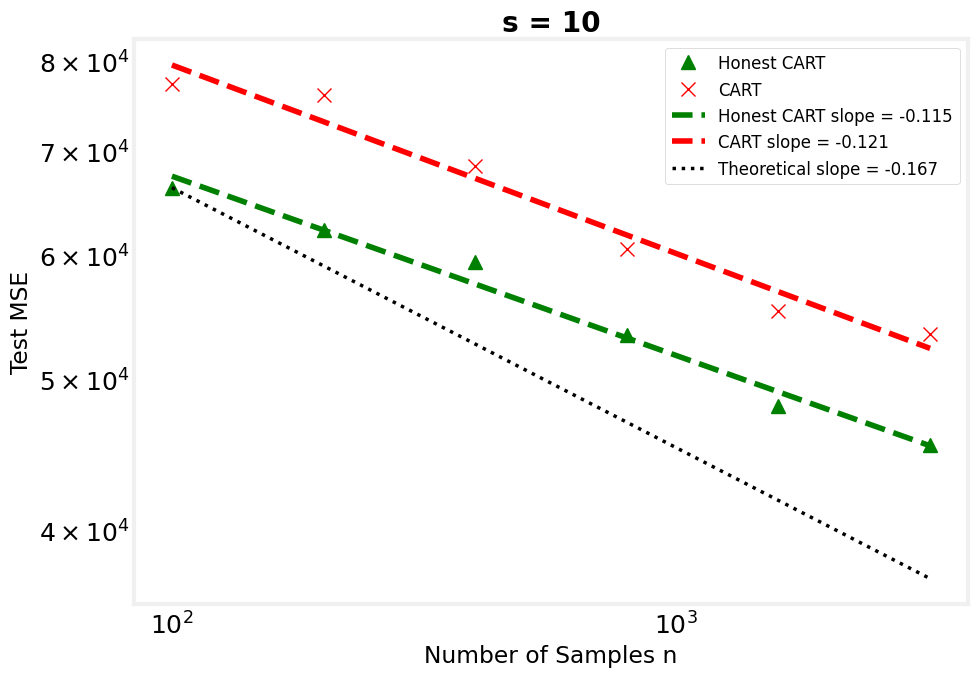

In [ ]:
s_to_plot = 10

# ---------------- Plotting style ----------------
plt.style.use("fivethirtyeight")
mpl.rcParams['lines.markersize'] = 10
mpl.rcParams['grid.linewidth'] = 1.5
mpl.rcParams['figure.facecolor'] = 'white'
mpl.rcParams['axes.facecolor'] = 'white'
mpl.rcParams['legend.fontsize'] = 12

# Find the corresponding row
sparsity_to_idx = {int(s): i for i, s in enumerate(sparsity)}
if s_to_plot not in sparsity_to_idx:
    raise ValueError(f"s={s_to_plot} not found in sparsity: {sparsity}")

idx = sparsity_to_idx[s_to_plot]

# Extract test MSE values
honest_scores = np.asarray(honest_CART_scores[idx], dtype=float)
cart_scores = np.asarray(CART_scores[idx], dtype=float)

# Get fitted slopes and intercepts
h_slope, h_int = get_fit(
    honest_CART_best_fit[idx], n_train, honest_scores
)
c_slope, c_int = get_fit(
    CART_best_fit[idx], n_train, cart_scores
)

# ---------------- Create figure ----------------
fig, ax = plt.subplots(figsize=(10, 7))

# Empirical test MSE
ax.plot(
    n_train, honest_scores,
    marker='^', linestyle='none', color='green',
    label='Honest CART'
)
ax.plot(
    n_train, cart_scores,
    marker='x', linestyle='none', color='red',
    label='CART'
)

# Fitted log-log trends
ax.plot(
    n_train, fit_curve(h_slope, h_int, n_train),
    linestyle='--', color='green',
    label=f'Honest CART slope = {h_slope:.3f}'
)
ax.plot(
    n_train, fit_curve(c_slope, c_int, n_train),
    linestyle='--', color='red',
    label=f'CART slope = {c_slope:.3f}'
)

# Theoretical reference rate
theoretical_slope = -2.0 / (s_to_plot + 2)

if honest_scores[0] > 0 and n_train[0] > 0:
    ref = fit_curve(
        theoretical_slope,
        np.log(honest_scores[0])
        - theoretical_slope * np.log(n_train[0]),
        n_train
    )
    ax.plot(
        n_train, ref,
        linestyle=':', color='black', linewidth=2.5,
        label=f'Theoretical slope = {theoretical_slope:.3f}'
    )

# Independent axis limits for this plot
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Number of Samples n')
ax.set_ylabel(r'Test MSE')
ax.set_title(f's = {s_to_plot}', fontweight='bold')
ax.grid(False)
ax.legend(loc='best', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()


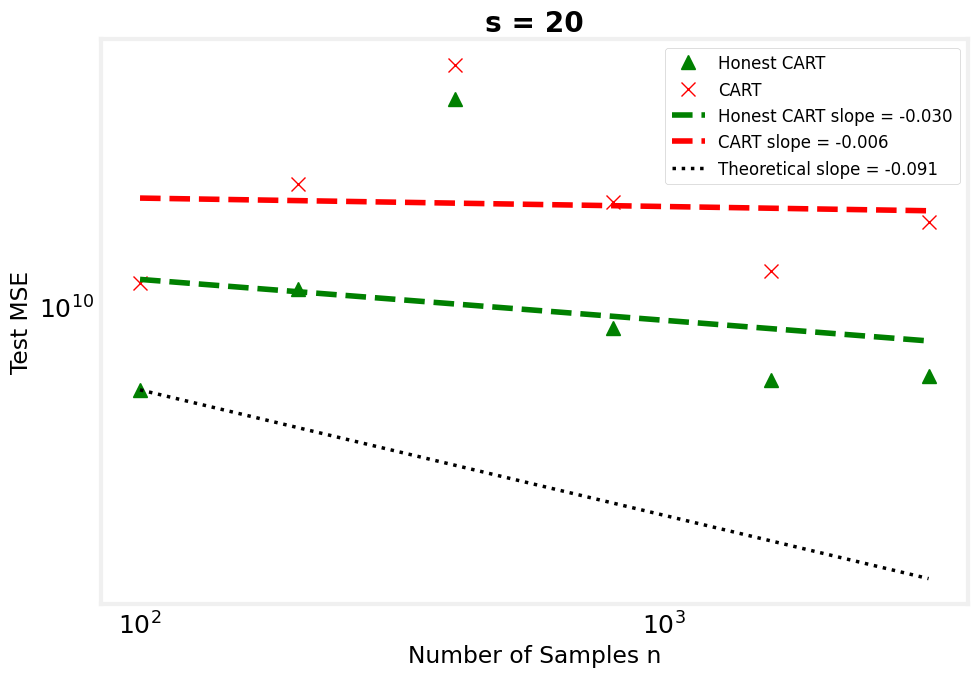

In [48]:
s_to_plot = 20

# ---------------- Plotting style ----------------
plt.style.use("fivethirtyeight")
mpl.rcParams['lines.markersize'] = 10
mpl.rcParams['grid.linewidth'] = 1.5
mpl.rcParams['figure.facecolor'] = 'white'
mpl.rcParams['axes.facecolor'] = 'white'
mpl.rcParams['legend.fontsize'] = 12

# Find the corresponding row
sparsity_to_idx = {int(s): i for i, s in enumerate(sparsity)}
if s_to_plot not in sparsity_to_idx:
    raise ValueError(f"s={s_to_plot} not found in sparsity: {sparsity}")

idx = sparsity_to_idx[s_to_plot]

# Extract test MSE values
honest_scores = np.asarray(honest_CART_scores[idx], dtype=float)
cart_scores = np.asarray(CART_scores[idx], dtype=float)

# Get fitted slopes and intercepts
h_slope, h_int = get_fit(
    honest_CART_best_fit[idx], n_train, honest_scores
)
c_slope, c_int = get_fit(
    CART_best_fit[idx], n_train, cart_scores
)

# ---------------- Create figure ----------------
fig, ax = plt.subplots(figsize=(10, 7))

# Empirical test MSE
ax.plot(
    n_train, honest_scores,
    marker='^', linestyle='none', color='green',
    label='Honest CART'
)
ax.plot(
    n_train, cart_scores,
    marker='x', linestyle='none', color='red',
    label='CART'
)

# Fitted log-log trends
ax.plot(
    n_train, fit_curve(h_slope, h_int, n_train),
    linestyle='--', color='green',
    label=f'Honest CART slope = {h_slope:.3f}'
)
ax.plot(
    n_train, fit_curve(c_slope, c_int, n_train),
    linestyle='--', color='red',
    label=f'CART slope = {c_slope:.3f}'
)

# Theoretical reference rate
theoretical_slope = -2.0 / (s_to_plot + 2)

if honest_scores[0] > 0 and n_train[0] > 0:
    ref = fit_curve(
        theoretical_slope,
        np.log(honest_scores[0])
        - theoretical_slope * np.log(n_train[0]),
        n_train
    )
    ax.plot(
        n_train, ref,
        linestyle=':', color='black', linewidth=2.5,
        label=f'Theoretical slope = {theoretical_slope:.3f}'
    )

# Independent axis limits for this plot
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Number of Samples n')
ax.set_ylabel(r'Test MSE')
ax.set_title(f's = {s_to_plot}', fontweight='bold')
ax.grid(False)
ax.legend(loc='best', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()


In [71]:
# s_to_plot = 10

# # ---------------- Plotting style ----------------
# plt.style.use("fivethirtyeight")
# mpl.rcParams['lines.markersize'] = 10
# mpl.rcParams['grid.linewidth'] = 1.5
# mpl.rcParams['figure.facecolor'] = 'white'
# mpl.rcParams['axes.facecolor'] = 'white'
# mpl.rcParams['legend.fontsize'] = 12

# # Find the corresponding row
# sparsity_to_idx = {int(s): i for i, s in enumerate(sparsity)}
# if s_to_plot not in sparsity_to_idx:
#     raise ValueError(f"s={s_to_plot} not found in sparsity: {sparsity}")

# idx = sparsity_to_idx[s_to_plot]

# # Extract and aggregate raw test MSE values across runs/folds
# honest_raw = np.asarray(honest_CART_scores[idx], dtype=float)
# cart_raw = np.asarray(CART_scores[idx], dtype=float)

# if honest_raw.ndim > 1:
#     honest_scores = np.mean(honest_raw, axis=1)
#     honest_errors = np.std(honest_raw, axis=1) / np.sqrt(honest_raw.shape[1])
# else:
#     honest_scores = honest_raw
#     honest_errors = None

# if cart_raw.ndim > 1:
#     cart_scores = np.mean(cart_raw, axis=1)
#     cart_errors = np.std(cart_raw, axis=1) / np.sqrt(cart_raw.shape[1])
# else:
#     cart_scores = cart_raw
#     cart_errors = None

# # Get fitted slopes and intercepts
# h_slope, h_int = get_fit(
#     honest_CART_best_fit[idx], n_train, honest_scores
# )
# c_slope, c_int = get_fit(
#     CART_best_fit[idx], n_train, cart_scores
# )

# # ---------------- Create figure ----------------
# fig, ax = plt.subplots(figsize=(10, 7))

# # Empirical test MSE with Error Bars
# ax.errorbar(
#     n_train, honest_scores, yerr=honest_errors,
#     marker='^', linestyle='none', color='green',
#     capsize=4, capthick=1.5, elinewidth=1.5,
#     label='Honest CART'
# )
# ax.errorbar(
#     n_train, cart_scores, yerr=cart_errors,
#     marker='x', linestyle='none', color='red',
#     capsize=4, capthick=1.5, elinewidth=1.5,
#     label='CART'
# )

# # Fitted log-log trends
# ax.plot(
#     n_train, fit_curve(h_slope, h_int, n_train),
#     linestyle='--', color='green',
#     label=f'Honest CART slope = {h_slope:.3f}'
# )
# ax.plot(
#     n_train, fit_curve(c_slope, c_int, n_train),
#     linestyle='--', color='red',
#     label=f'CART slope = {c_slope:.3f}'
# )

# # Theoretical reference rate
# theoretical_slope = -2.0 / (s_to_plot + 2)

# if honest_scores[0] > 0 and n_train[0] > 0:
#     ref = fit_curve(
#         theoretical_slope,
#         np.log(honest_scores[0]) - theoretical_slope * np.log(n_train[0]),
#         n_train
#     )
#     ax.plot(
#         n_train, ref,
#         linestyle=':', color='black', linewidth=2.5,
#         label=f'Theoretical slope = {theoretical_slope:.3f}'
#     )

# # Independent axis limits for this plot
# ax.set_xscale('log')
# ax.set_yscale('log')
# ax.set_xlabel('Number of Samples n')
# ax.set_ylabel(r'Test MSE')
# ax.set_title(f's = {s_to_plot}', fontweight='bold')
# ax.grid(False)
# ax.legend(loc='best', frameon=True, facecolor='white', framealpha=0.9)

# plt.tight_layout()
# plt.show()